<a href="https://colab.research.google.com/github/naubergois/curso-yolo-colab/blob/main/notebooks/01-deteccao-em-imagem.ipynb" target="_blank"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Abrir no Colab"/></a>

# 1. Detecção de objetos em uma imagem

Uma rede de detecção olha a foto inteira de uma vez e devolve caixas: onde está cada objeto, que classe ele é e quanta certeza ela tem. É daí que vem o nome YOLO, *You Only Look Once*.

O modelo usado aqui é o `yolov8n`, a versão *nano*. Tem uns 6 MB, roda bem até sem GPU e já sabe reconhecer as 80 classes do dataset COCO: pessoa, carro, ônibus, cachorro, celular e por aí vai.

> No Colab: **Ambiente de execução → Executar tudo**. GPU é opcional nesta aula.

In [1]:
!pip install -q ultralytics

In [2]:
import base64
import subprocess
import urllib.request
from pathlib import Path

from IPython.display import HTML, display


def baixar(url, destino):
    if not Path(destino).exists():
        urllib.request.urlretrieve(url, destino)
    print(f"{destino}: {Path(destino).stat().st_size / 1e6:.1f} MB")
    return destino


def mostrar_video(caminho, largura=720):
    """Converte para H.264 (o navegador não toca mp4v) e embute no notebook."""
    web = str(Path(caminho).with_suffix("")) + "_web.mp4"
    subprocess.run(
        ["ffmpeg", "-y", "-loglevel", "error", "-i", caminho,
         "-vcodec", "libx264", "-pix_fmt", "yuv420p", "-movflags", "+faststart", web],
        check=True,
    )
    dados = base64.b64encode(Path(web).read_bytes()).decode()
    display(HTML(f'<video width="{largura}" controls autoplay muted loop>'
                 f'<source src="data:video/mp4;base64,{dados}" type="video/mp4"></video>'))
    return web


def baixar_para_maquina(caminho):
    try:
        from google.colab import files
        files.download(caminho)
    except ImportError:
        print(f"Fora do Colab: o arquivo está em {Path(caminho).resolve()}")

## Carregar o modelo e a imagem

Na primeira chamada, `YOLO("yolov8n.pt")` baixa os pesos já treinados. A imagem é a foto de um ônibus numa rua, que a própria Ultralytics usa como teste.

In [3]:
from ultralytics import YOLO
import matplotlib.pyplot as plt

model = YOLO("yolov8n.pt")
imagem = baixar("https://ultralytics.com/images/bus.jpg", "bus.jpg")

bus.jpg: 0.1 MB


## Rodar a detecção

`model(imagem)` devolve uma lista com um resultado por imagem. Cada resultado traz as caixas (`boxes`), com coordenadas, classe e confiança. O `plot()` desenha tudo em cima da foto.

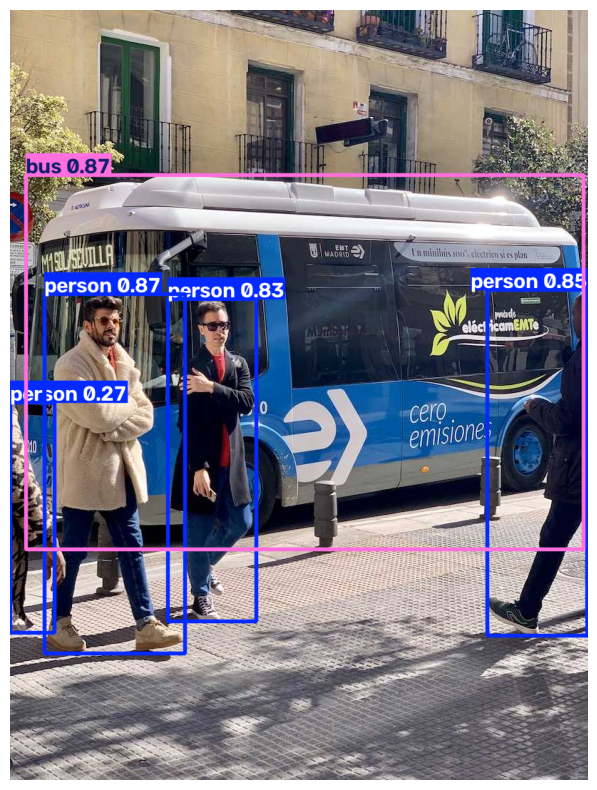

In [4]:
resultado = model(imagem, verbose=False)[0]

plt.figure(figsize=(8, 10))
plt.imshow(resultado.plot()[:, :, ::-1])  # BGR -> RGB
plt.axis("off")
plt.show()

## Ler as caixas como dados

Desenhar é bom para olhar. Para usar num sistema, você quer os números: classe, confiança e posição de cada caixa.

In [5]:
for caixa in resultado.boxes:
    classe = model.names[int(caixa.cls)]
    conf = float(caixa.conf)
    x1, y1, x2, y2 = caixa.xyxy[0].tolist()
    print(f"{classe:10s} {conf:5.0%}  ({x1:4.0f},{y1:4.0f}) -> ({x2:4.0f},{y2:4.0f})")

assert len(resultado.boxes) > 0, "nenhum objeto detectado"

bus          87%  (  23, 231) -> ( 805, 757)
person       87%  (  48, 399) -> ( 245, 903)
person       85%  ( 669, 393) -> ( 810, 877)
person       83%  ( 222, 406) -> ( 345, 858)
person       27%  (   0, 550) -> (  63, 874)


## Ajustar a confiança

Por padrão o modelo descarta o que tem menos de 25% de confiança. Subir o `conf` limpa os falsos positivos, mas também perde objetos difíceis. Compare:

In [6]:
for limite in (0.25, 0.5, 0.8):
    n = len(model(imagem, conf=limite, verbose=False)[0].boxes)
    print(f"conf >= {limite:.2f}: {n} objetos")

conf >= 0.25: 5 objetos
conf >= 0.50: 4 objetos
conf >= 0.80: 4 objetos


## O que fica

Uma linha de código já dá caixas, classes e confianças. O que o modelo **não** faz sozinho é lembrar do objeto de um quadro para o outro, e isso é assunto do rastreamento, na aula 3.

Para experimentar com uma foto sua, troque a URL em `baixar(...)` ou suba o arquivo pelo painel lateral do Colab.